In [1]:
import pandas as pd
from pathlib import Path

# ============================================================
# FIND FAOSTAT CSV FILES
# ============================================================

downloads = Path(r"C:\Users\franc")

faostat_files = [
    f for f in downloads.rglob("*.csv")
    if "FAOSTAT" in f.name.upper()
]

print("FAOSTAT CSV files found:", len(faostat_files))

for i, f in enumerate(faostat_files, start=1):
    print(f"{i}. {f}")

FAOSTAT CSV files found: 1
1. C:\Users\franc\FAOSTAT_data_en_9-7-2026.csv


In [2]:
import pandas as pd

# ============================================================
# LOAD FAOSTAT DATA
# ============================================================

faostat_file = r"C:\Users\franc\FAOSTAT_data_en_9-7-2026.csv"

fao = pd.read_csv(faostat_file, encoding="utf-8-sig")

print("Shape:", fao.shape)

print("\nColumns:")
for col in fao.columns:
    print(col)

print("\nFirst 10 rows:")
print(fao.head(10))

# ============================================================
# CHECK IMPORTANT FIELDS
# ============================================================

if "Area" in fao.columns:
    print("\nAreas:")
    print(fao["Area"].dropna().unique())

if "Item" in fao.columns:
    print("\nItems:")
    print(fao["Item"].dropna().unique())

if "Element" in fao.columns:
    print("\nElements:")
    print(fao["Element"].dropna().unique())

if "Year" in fao.columns:
    print("\nYear range:")
    print(fao["Year"].min(), "to", fao["Year"].max())
    print("Number of unique years:", fao["Year"].nunique())

if "Unit" in fao.columns:
    print("\nUnits:")
    print(fao[["Element", "Unit"]].drop_duplicates().to_string(index=False))

Shape: (88, 15)

Columns:
Domain Code
Domain
Area Code (M49)
Area
Element Code
Element
Item Code (CPC)
Item
Year Code
Year
Unit
Value
Flag
Flag Description
Note

First 10 rows:
  Domain Code                        Domain  Area Code (M49)          Area  \
0         QCL  Crops and livestock products              710  South Africa   
1         QCL  Crops and livestock products              710  South Africa   
2         QCL  Crops and livestock products              710  South Africa   
3         QCL  Crops and livestock products              710  South Africa   
4         QCL  Crops and livestock products              710  South Africa   
5         QCL  Crops and livestock products              710  South Africa   
6         QCL  Crops and livestock products              710  South Africa   
7         QCL  Crops and livestock products              710  South Africa   
8         QCL  Crops and livestock products              710  South Africa   
9         QCL  Crops and livestock products

In [3]:
# ============================================================
# PREPARE FAOSTAT MAIZE DATA
# South Africa, 1982–2024
# ============================================================

# Separate yield and harvested area
fao_yield = fao[
    fao["Element"] == "Yield"
][["Year", "Value"]].copy()

fao_area = fao[
    fao["Element"] == "Area harvested"
][["Year", "Value"]].copy()

# Rename columns
fao_yield.columns = [
    "Harvest_Year",
    "FAOSTAT_Yield_kg_ha"
]

fao_area.columns = [
    "Harvest_Year",
    "FAOSTAT_Area_Harvested_ha"
]

# ============================================================
# CONVERT YIELD: kg/ha -> tonnes/ha
# ============================================================

fao_yield["FAOSTAT_Yield_t_ha"] = (
    fao_yield["FAOSTAT_Yield_kg_ha"] / 1000
)

# ============================================================
# MERGE YIELD + HARVESTED AREA
# ============================================================

faostat_maize = pd.merge(
    fao_yield,
    fao_area,
    on="Harvest_Year",
    how="inner"
)

# Restrict to common analysis period
faostat_maize = faostat_maize[
    faostat_maize["Harvest_Year"].between(1982, 2024)
].copy()

faostat_maize = (
    faostat_maize
    .sort_values("Harvest_Year")
    .reset_index(drop=True)
)

# ============================================================
# INSPECT
# ============================================================

print("Shape:", faostat_maize.shape)

print(
    "Years:",
    faostat_maize["Harvest_Year"].min(),
    "to",
    faostat_maize["Harvest_Year"].max()
)

print(
    "Unique years:",
    faostat_maize["Harvest_Year"].nunique()
)

print("\nMissing values:")
print(faostat_maize.isna().sum())

print("\nFirst 10 rows:")
print(faostat_maize.head(10).to_string(index=False))

print("\nLast 5 rows:")
print(faostat_maize.tail().to_string(index=False))

Shape: (43, 4)
Years: 1982 to 2024
Unique years: 43

Missing values:
Harvest_Year                 0
FAOSTAT_Yield_kg_ha          0
FAOSTAT_Yield_t_ha           0
FAOSTAT_Area_Harvested_ha    0
dtype: int64

First 10 rows:
 Harvest_Year  FAOSTAT_Yield_kg_ha  FAOSTAT_Yield_t_ha  FAOSTAT_Area_Harvested_ha
         1982               1882.7              1.8827                  4664000.0
         1983                940.0              0.9400                  4680000.0
         1984                991.3              0.9913                  4839000.0
         1985               1875.6              1.8756                  4502000.0
         1986               1780.9              1.7809                  4829000.0
         1987               1558.4              1.5584                  5063000.0
         1988               1619.5              1.6195                  4736000.0
         1989               2840.5              2.8405                  4394000.0
         1990               2205.1      

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

# ============================================================
# FAOSTAT MAIZE YIELD
# SAME LOWESS METHOD USED FOR CEC
# ============================================================

fao_analysis = faostat_maize.copy()

# LOWESS trend
lowess_result = lowess(
    endog=fao_analysis["FAOSTAT_Yield_t_ha"],
    exog=fao_analysis["Harvest_Year"],
    frac=0.30,
    return_sorted=False
)

fao_analysis["LOWESS_Trend_t_ha"] = lowess_result

# ============================================================
# MAIZE YIELD ANOMALY (MYA)
# Same formula used for CEC
# ============================================================

fao_analysis["MYA"] = (
    fao_analysis["FAOSTAT_Yield_t_ha"]
    - fao_analysis["LOWESS_Trend_t_ha"]
) / fao_analysis["LOWESS_Trend_t_ha"]

fao_analysis["MYA_percent"] = (
    fao_analysis["MYA"] * 100
)

# ============================================================
# SAVE
# ============================================================

output_csv = (
    r"C:\Users\franc\faostat_maize_yield_anomalies_LOWESS_1982_2024.csv"
)

fao_analysis.to_csv(
    output_csv,
    index=False
)

# ============================================================
# CHECK RESULTS
# ============================================================

print("FAOSTAT LOWESS analysis complete.")
print("Years:",
      fao_analysis["Harvest_Year"].min(),
      "to",
      fao_analysis["Harvest_Year"].max())

print("Number of years:", len(fao_analysis))

print("\nMYA summary:")
print(fao_analysis["MYA"].describe())

print("\nSelected event years:")

event_years = [1992, 1993, 2002, 2016, 2019, 2024]

print(
    fao_analysis[
        fao_analysis["Harvest_Year"].isin(event_years)
    ][
        [
            "Harvest_Year",
            "FAOSTAT_Yield_t_ha",
            "LOWESS_Trend_t_ha",
            "MYA",
            "MYA_percent"
        ]
    ].to_string(index=False)
)

print("\nSaved:")
print(output_csv)

FAOSTAT LOWESS analysis complete.
Years: 1982 to 2024
Number of years: 43

MYA summary:
count    43.000000
mean     -0.024777
std       0.206186
min      -0.657668
25%      -0.118164
50%       0.000510
75%       0.071501
max       0.507131
Name: MYA, dtype: float64

Selected event years:
 Harvest_Year  FAOSTAT_Yield_t_ha  LOWESS_Trend_t_ha       MYA  MYA_percent
         1992              0.7853           2.293970 -0.657668   -65.766774
         1993              2.2840           2.338672 -0.023377    -2.337736
         2002              2.8516           2.797369  0.019386     1.938644
         2016              3.7120           4.704185 -0.210915   -21.091543
         2019              4.5539           5.169618 -0.119103   -11.910312
         2024              4.8743           6.371339 -0.234965   -23.496463

Saved:
C:\Users\franc\faostat_maize_yield_anomalies_LOWESS_1982_2024.csv


Number of observations: 43
Years: 1982 to 2024

FAOSTAT × CDHW
Pearson r = -0.4841
p-value = 0.001006


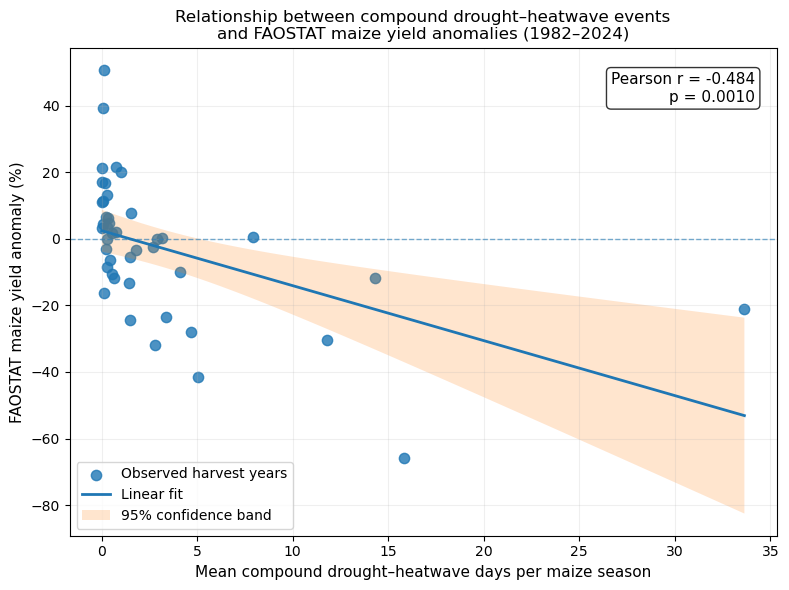


Saved:
C:\Users\franc\faostat_cdhw_maize_yield_correlation_1982_2024_95CI.png


In [5]:
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, linregress, t

# ============================================================
# 1. LOAD FAOSTAT YIELD ANOMALIES
# ============================================================

fao_file = (
    r"C:\Users\franc\faostat_maize_yield_anomalies_LOWESS_1982_2024.csv"
)

fao = pd.read_csv(fao_file)

# ============================================================
# 2. LOAD CDHW DATA AND MAIZE MASK
# ============================================================

cdhw_file = (
    r"C:\Users\franc\cdhw_severity_1982_2025.nc"
)

mask_file = (
    r"C:\Users\franc\spam2020_sa_maize_mask_cdhw_grid.nc"
)

ds_cdhw = xr.open_dataset(
    cdhw_file,
    decode_timedelta=False
)

ds_mask = xr.open_dataset(
    mask_file,
    decode_timedelta=False
)

# ============================================================
# 3. CDHW DAYS OVER MAIZE-GROWING GRID CELLS
# ============================================================

cdhw = ds_cdhw["cdhw_simultaneous_days"]

maize_mask = (
    ds_mask["maize_cultivated"] == 1
)

cdhw_maize = cdhw.where(maize_mask)

cdhw_maize_mean = cdhw_maize.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

cdhw_annual = pd.DataFrame({
    "Harvest_Year":
        ds_cdhw["harvest_year"].values.astype(int),

    "Mean_CDHW_Days":
        cdhw_maize_mean.values
})

# ============================================================
# 4. MERGE FAOSTAT AND CDHW
# ============================================================

analysis = pd.merge(
    fao[
        [
            "Harvest_Year",
            "MYA",
            "MYA_percent"
        ]
    ],
    cdhw_annual,
    on="Harvest_Year",
    how="inner"
)

analysis = analysis.dropna(
    subset=["MYA_percent", "Mean_CDHW_Days"]
).copy()

print("Number of observations:", len(analysis))

print(
    "Years:",
    analysis["Harvest_Year"].min(),
    "to",
    analysis["Harvest_Year"].max()
)

# ============================================================
# 5. PEARSON CORRELATION
# ============================================================

x = analysis["Mean_CDHW_Days"].values
y = analysis["MYA_percent"].values

r, p = pearsonr(x, y)

print("\nFAOSTAT × CDHW")
print("Pearson r =", round(r, 4))
print("p-value =", round(p, 6))

# ============================================================
# 6. LINEAR REGRESSION
# ============================================================

reg = linregress(x, y)

slope = reg.slope
intercept = reg.intercept

x_line = np.linspace(
    x.min(),
    x.max(),
    300
)

y_line = (
    intercept +
    slope * x_line
)

# ============================================================
# 7. 95% CONFIDENCE BAND
# ============================================================

n = len(x)

y_hat = (
    intercept +
    slope * x
)

residuals = y - y_hat

residual_standard_error = np.sqrt(
    np.sum(residuals**2) /
    (n - 2)
)

x_mean = np.mean(x)

Sxx = np.sum(
    (x - x_mean)**2
)

t_crit = t.ppf(
    0.975,
    df=n - 2
)

se_fit = residual_standard_error * np.sqrt(
    (1 / n) +
    ((x_line - x_mean)**2 / Sxx)
)

ci_lower = (
    y_line -
    t_crit * se_fit
)

ci_upper = (
    y_line +
    t_crit * se_fit
)

# ============================================================
# 8. PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

# Observations
ax.scatter(
    x,
    y,
    s=55,
    alpha=0.8,
    label="Observed harvest years"
)

# Regression line
ax.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear fit"
)

# 95% confidence band
ax.fill_between(
    x_line,
    ci_lower,
    ci_upper,
    alpha=0.20,
    label="95% confidence band"
)

# Zero anomaly reference
ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

# ============================================================
# 9. LABELS
# ============================================================

ax.set_xlabel(
    "Mean compound drought–heatwave days per maize season",
    fontsize=11
)

ax.set_ylabel(
    "FAOSTAT maize yield anomaly (%)",
    fontsize=11
)

ax.set_title(
    "Relationship between compound drought–heatwave events\n"
    "and FAOSTAT maize yield anomalies (1982–2024)",
    fontsize=12
)

# ============================================================
# 10. CORRELATION ANNOTATION
# ============================================================

ax.text(
    0.97,
    0.95,
    f"Pearson r = {r:.3f}\n"
    f"p = {p:.4f}",
    transform=ax.transAxes,
    horizontalalignment="right",
    verticalalignment="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.8
    )
)

ax.legend(
    loc="lower left",
    frameon=True
)

ax.grid(alpha=0.2)

plt.tight_layout()

# ============================================================
# 11. SAVE
# ============================================================

output_file = (
    r"C:\Users\franc\faostat_cdhw_maize_yield_correlation_1982_2024_95CI.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(output_file)

In [6]:
import xarray as xr

# ============================================================
# FILES
# ============================================================

hw_file = r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"

fd_file = r"C:\Users\franc\flash_drought_events_1982_2025_final.nc"

# ============================================================
# OPEN SAFELY
# ============================================================

hw = xr.open_dataset(
    hw_file,
    decode_timedelta=False
)

fd = xr.open_dataset(
    fd_file,
    decode_timedelta=False
)

# ============================================================
# INSPECT WITHOUT print(ds)
# ============================================================

print("========== HEATWAVE ==========")

print("\nDimensions:")
print(dict(hw.sizes))

print("\nCoordinates:")
for c in hw.coords:
    print(
        c,
        hw[c].dims,
        hw[c].shape
    )

print("\nVariables:")
for v in hw.data_vars:
    print(
        v,
        hw[v].dims,
        hw[v].shape,
        "units =", hw[v].attrs.get("units")
    )


print("\n\n========== FLASH DROUGHT ==========")

print("\nDimensions:")
print(dict(fd.sizes))

print("\nCoordinates:")
for c in fd.coords:
    print(
        c,
        fd[c].dims,
        fd[c].shape
    )

print("\nVariables:")
for v in fd.data_vars:
    print(
        v,
        fd[v].dims,
        fd[v].shape,
        "units =", fd[v].attrs.get("units")
    )

========== HEATWAVE ==========

Dimensions:
{'harvest_year': 44, 'latitude': 57, 'longitude': 89}

Coordinates:
number () ()
latitude ('latitude',) (57,)
longitude ('longitude',) (89,)
harvest_year ('harvest_year',) (44,)

Variables:
hw_duration ('harvest_year', 'latitude', 'longitude') (44, 57, 89) units = K
fd_duration ('harvest_year', 'latitude', 'longitude') (44, 57, 89) units = days


========== FLASH DROUGHT ==========

Dimensions:
{'harvest_year': 44, 'lat': 141, 'lon': 220}

Coordinates:
harvest_year ('harvest_year',) (44,)
lat ('lat',) (141,)
lon ('lon',) (220,)

Variables:
fd_frequency ('harvest_year', 'lat', 'lon') (44, 141, 220) units = None
fd_total_duration ('harvest_year', 'lat', 'lon') (44, 141, 220) units = None
fd_max_duration ('harvest_year', 'lat', 'lon') (44, 141, 220) units = None
fd_cumulative_intensity ('harvest_year', 'lat', 'lon') (44, 141, 220) units = None
fd_peak_intensity ('harvest_year', 'lat', 'lon') (44, 141, 220) units = None


Number of observations: 44
Years: 1982 to 2025

CEC × Heatwave
Pearson r = -0.5022
p-value = 0.000514


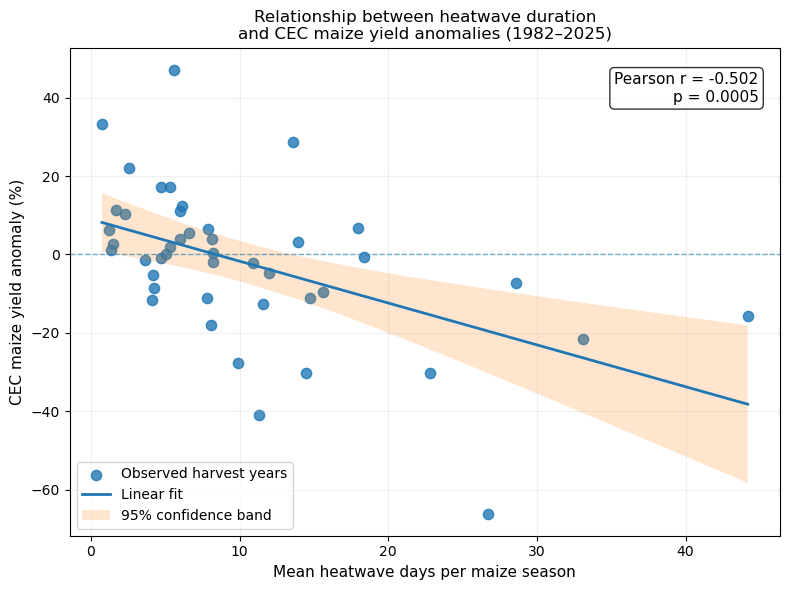


Saved:
C:\Users\franc\cec_heatwave_maize_yield_correlation_1982_2025_95CI.png


In [7]:
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, linregress, t

# ============================================================
# 1. LOAD CEC YIELD ANOMALIES
# ============================================================

cec_file = (
    r"C:\Users\franc\maize_yield_anomalies_LOWESS_1982_2025.csv"
)

cec = pd.read_csv(cec_file)

# ============================================================
# 2. LOAD HEATWAVE DATA + MAIZE MASK
# ============================================================

hw_file = (
    r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"
)

mask_file = (
    r"C:\Users\franc\spam2020_sa_maize_mask_cdhw_grid.nc"
)

hw_ds = xr.open_dataset(
    hw_file,
    decode_timedelta=False
)

mask_ds = xr.open_dataset(
    mask_file,
    decode_timedelta=False
)

# ============================================================
# 3. MEAN HEATWAVE DURATION OVER MAIZE-GROWING CELLS
# ============================================================

hw_duration = hw_ds["hw_duration"]

maize_mask = (
    mask_ds["maize_cultivated"] == 1
)

hw_maize = hw_duration.where(maize_mask)

hw_mean = hw_maize.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

hw_annual = pd.DataFrame({
    "Harvest_Year":
        hw_ds["harvest_year"].values.astype(int),

    "Mean_Heatwave_Days":
        hw_mean.values
})

# ============================================================
# 4. MERGE WITH CEC YIELD ANOMALIES
# ============================================================

analysis = pd.merge(
    cec[
        [
            "Harvest_Year",
            "MYA",
            "MYA_percent"
        ]
    ],
    hw_annual,
    on="Harvest_Year",
    how="inner"
)

analysis = analysis.dropna(
    subset=[
        "MYA_percent",
        "Mean_Heatwave_Days"
    ]
).copy()

print("Number of observations:", len(analysis))

print(
    "Years:",
    analysis["Harvest_Year"].min(),
    "to",
    analysis["Harvest_Year"].max()
)

# ============================================================
# 5. PEARSON CORRELATION
# ============================================================

x = analysis["Mean_Heatwave_Days"].values
y = analysis["MYA_percent"].values

r, p = pearsonr(x, y)

print("\nCEC × Heatwave")
print("Pearson r =", round(r, 4))
print("p-value =", round(p, 6))

# ============================================================
# 6. LINEAR REGRESSION
# ============================================================

reg = linregress(x, y)

slope = reg.slope
intercept = reg.intercept

x_line = np.linspace(
    x.min(),
    x.max(),
    300
)

y_line = (
    intercept +
    slope * x_line
)

# ============================================================
# 7. 95% CONFIDENCE BAND
# ============================================================

n = len(x)

y_hat = (
    intercept +
    slope * x
)

residuals = y - y_hat

residual_standard_error = np.sqrt(
    np.sum(residuals**2) /
    (n - 2)
)

x_mean = np.mean(x)

Sxx = np.sum(
    (x - x_mean)**2
)

t_crit = t.ppf(
    0.975,
    df=n - 2
)

se_fit = residual_standard_error * np.sqrt(
    (1 / n) +
    ((x_line - x_mean)**2 / Sxx)
)

ci_lower = (
    y_line -
    t_crit * se_fit
)

ci_upper = (
    y_line +
    t_crit * se_fit
)

# ============================================================
# 8. PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.scatter(
    x,
    y,
    s=55,
    alpha=0.8,
    label="Observed harvest years"
)

ax.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear fit"
)

ax.fill_between(
    x_line,
    ci_lower,
    ci_upper,
    alpha=0.20,
    label="95% confidence band"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

# ============================================================
# 9. LABELS
# ============================================================

ax.set_xlabel(
    "Mean heatwave days per maize season",
    fontsize=11
)

ax.set_ylabel(
    "CEC maize yield anomaly (%)",
    fontsize=11
)

ax.set_title(
    "Relationship between heatwave duration\n"
    "and CEC maize yield anomalies (1982–2025)",
    fontsize=12
)

# ============================================================
# 10. CORRELATION ANNOTATION
# ============================================================

ax.text(
    0.97,
    0.95,
    f"Pearson r = {r:.3f}\n"
    f"p = {p:.4f}",
    transform=ax.transAxes,
    horizontalalignment="right",
    verticalalignment="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.8
    )
)

ax.legend(
    loc="lower left",
    frameon=True
)

ax.grid(alpha=0.2)

plt.tight_layout()

# ============================================================
# 11. SAVE
# ============================================================

output_file = (
    r"C:\Users\franc\cec_heatwave_maize_yield_correlation_1982_2025_95CI.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(output_file)

Number of observations: 43
Years: 1982 to 2024

FAOSTAT × Heatwave
Pearson r = -0.5499
p-value = 0.000134


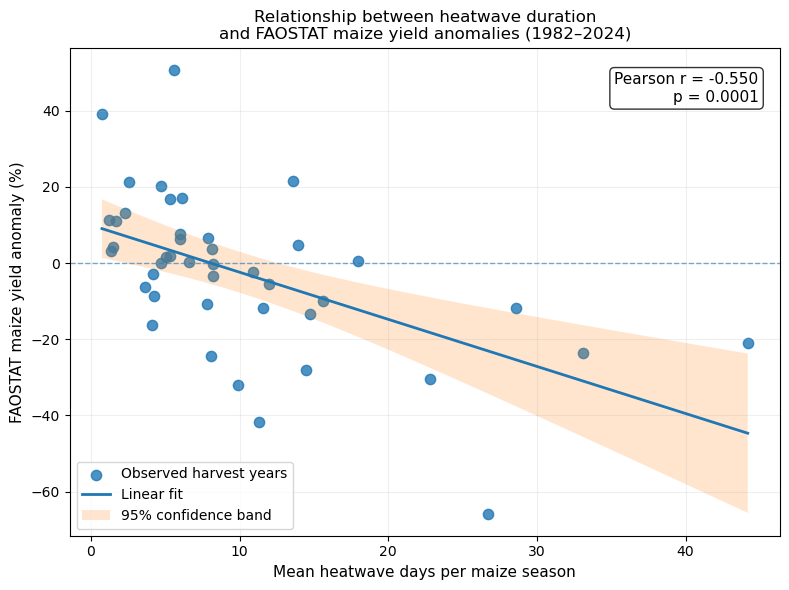


Saved:
C:\Users\franc\faostat_heatwave_maize_yield_correlation_1982_2024_95CI.png


In [8]:
# ============================================================
# HEATWAVE × FAOSTAT MAIZE YIELD ANOMALIES
# WITH 95% CONFIDENCE BAND
# ============================================================

import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, linregress, t

# ============================================================
# 1. LOAD FAOSTAT YIELD ANOMALIES
# ============================================================

fao_file = (
    r"C:\Users\franc\faostat_maize_yield_anomalies_LOWESS_1982_2024.csv"
)

fao = pd.read_csv(fao_file)

# ============================================================
# 2. LOAD HEATWAVE DATA + MAIZE MASK
# ============================================================

hw_file = (
    r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"
)

mask_file = (
    r"C:\Users\franc\spam2020_sa_maize_mask_cdhw_grid.nc"
)

hw_ds = xr.open_dataset(
    hw_file,
    decode_timedelta=False
)

mask_ds = xr.open_dataset(
    mask_file,
    decode_timedelta=False
)

# ============================================================
# 3. MEAN HEATWAVE DURATION OVER MAIZE-GROWING CELLS
# ============================================================

hw_duration = hw_ds["hw_duration"]

maize_mask = (
    mask_ds["maize_cultivated"] == 1
)

hw_maize = hw_duration.where(maize_mask)

hw_mean = hw_maize.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

hw_annual = pd.DataFrame({
    "Harvest_Year":
        hw_ds["harvest_year"].values.astype(int),

    "Mean_Heatwave_Days":
        hw_mean.values
})

# ============================================================
# 4. MERGE WITH FAOSTAT YIELD ANOMALIES
# ============================================================

analysis = pd.merge(
    fao[
        [
            "Harvest_Year",
            "MYA",
            "MYA_percent"
        ]
    ],
    hw_annual,
    on="Harvest_Year",
    how="inner"
)

analysis = analysis.dropna(
    subset=[
        "MYA_percent",
        "Mean_Heatwave_Days"
    ]
).copy()

print("Number of observations:", len(analysis))

print(
    "Years:",
    analysis["Harvest_Year"].min(),
    "to",
    analysis["Harvest_Year"].max()
)

# ============================================================
# 5. PEARSON CORRELATION
# ============================================================

x = analysis["Mean_Heatwave_Days"].values
y = analysis["MYA_percent"].values

r, p = pearsonr(x, y)

print("\nFAOSTAT × Heatwave")
print("Pearson r =", round(r, 4))
print("p-value =", round(p, 6))

# ============================================================
# 6. LINEAR REGRESSION
# ============================================================

reg = linregress(x, y)

slope = reg.slope
intercept = reg.intercept

x_line = np.linspace(
    x.min(),
    x.max(),
    300
)

y_line = intercept + slope * x_line

# ============================================================
# 7. 95% CONFIDENCE BAND
# ============================================================

n = len(x)

y_hat = intercept + slope * x

residuals = y - y_hat

residual_standard_error = np.sqrt(
    np.sum(residuals**2) /
    (n - 2)
)

x_mean = np.mean(x)

Sxx = np.sum(
    (x - x_mean)**2
)

t_crit = t.ppf(
    0.975,
    df=n - 2
)

se_fit = residual_standard_error * np.sqrt(
    (1 / n) +
    ((x_line - x_mean)**2 / Sxx)
)

ci_lower = y_line - t_crit * se_fit
ci_upper = y_line + t_crit * se_fit

# ============================================================
# 8. PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.scatter(
    x,
    y,
    s=55,
    alpha=0.8,
    label="Observed harvest years"
)

ax.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear fit"
)

ax.fill_between(
    x_line,
    ci_lower,
    ci_upper,
    alpha=0.20,
    label="95% confidence band"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

# ============================================================
# 9. LABELS
# ============================================================

ax.set_xlabel(
    "Mean heatwave days per maize season",
    fontsize=11
)

ax.set_ylabel(
    "FAOSTAT maize yield anomaly (%)",
    fontsize=11
)

ax.set_title(
    "Relationship between heatwave duration\n"
    "and FAOSTAT maize yield anomalies (1982–2024)",
    fontsize=12
)

# ============================================================
# 10. CORRELATION ANNOTATION
# ============================================================

ax.text(
    0.97,
    0.95,
    f"Pearson r = {r:.3f}\n"
    f"p = {p:.4f}",
    transform=ax.transAxes,
    horizontalalignment="right",
    verticalalignment="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.8
    )
)

ax.legend(
    loc="lower left",
    frameon=True
)

ax.grid(alpha=0.2)

plt.tight_layout()

# ============================================================
# 11. SAVE
# ============================================================

output_file = (
    r"C:\Users\franc\faostat_heatwave_maize_yield_correlation_1982_2024_95CI.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(output_file)

Regridded flash-drought shape: (44, 57, 89)
Number of observations: 44
Years: 1982 to 2025

CEC × Flash drought
Pearson r = -0.5407
p-value = 0.000151


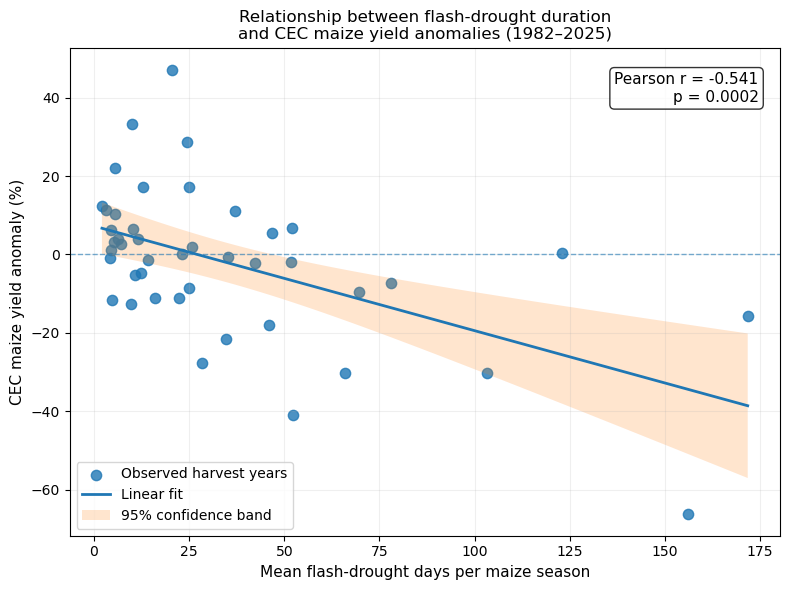


Saved:
C:\Users\franc\cec_flash_drought_maize_yield_correlation_1982_2025_95CI.png


In [9]:
# ============================================================
# FLASH DROUGHT × CEC MAIZE YIELD ANOMALIES
# WITH 95% CONFIDENCE BAND
# ============================================================

import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, linregress, t

# ============================================================
# 1. LOAD CEC YIELD ANOMALIES
# ============================================================

cec_file = (
    r"C:\Users\franc\maize_yield_anomalies_LOWESS_1982_2025.csv"
)

cec = pd.read_csv(cec_file)

# ============================================================
# 2. LOAD FLASH DROUGHT + MAIZE MASK
# ============================================================

fd_file = (
    r"C:\Users\franc\flash_drought_events_1982_2025_final.nc"
)

mask_file = (
    r"C:\Users\franc\spam2020_sa_maize_mask_cdhw_grid.nc"
)

fd_ds = xr.open_dataset(
    fd_file,
    decode_timedelta=False
)

mask_ds = xr.open_dataset(
    mask_file,
    decode_timedelta=False
)

# ============================================================
# 3. GET TOTAL FLASH-DROUGHT DURATION
# ============================================================

fd_duration = fd_ds["fd_total_duration"]

# Rename coordinates so they match the maize grid
fd_duration = fd_duration.rename({
    "lat": "latitude",
    "lon": "longitude"
})

# ============================================================
# 4. REGRID FLASH DROUGHT TO MAIZE/CDHW GRID
# ============================================================

fd_regridded = fd_duration.interp(
    latitude=mask_ds["latitude"],
    longitude=mask_ds["longitude"],
    method="nearest"
)

print(
    "Regridded flash-drought shape:",
    fd_regridded.shape
)

# ============================================================
# 5. APPLY MAIZE-GROWING MASK
# ============================================================

maize_mask = (
    mask_ds["maize_cultivated"] == 1
)

fd_maize = fd_regridded.where(
    maize_mask
)

fd_mean = fd_maize.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

fd_annual = pd.DataFrame({
    "Harvest_Year":
        fd_ds["harvest_year"].values.astype(int),

    "Mean_Flash_Drought_Days":
        fd_mean.values
})

# ============================================================
# 6. MERGE WITH CEC YIELD ANOMALIES
# ============================================================

analysis = pd.merge(
    cec[
        [
            "Harvest_Year",
            "MYA",
            "MYA_percent"
        ]
    ],
    fd_annual,
    on="Harvest_Year",
    how="inner"
)

analysis = analysis.dropna(
    subset=[
        "MYA_percent",
        "Mean_Flash_Drought_Days"
    ]
).copy()

print("Number of observations:", len(analysis))

print(
    "Years:",
    analysis["Harvest_Year"].min(),
    "to",
    analysis["Harvest_Year"].max()
)

# ============================================================
# 7. PEARSON CORRELATION
# ============================================================

x = analysis[
    "Mean_Flash_Drought_Days"
].values

y = analysis[
    "MYA_percent"
].values

r, p = pearsonr(x, y)

print("\nCEC × Flash drought")
print("Pearson r =", round(r, 4))
print("p-value =", round(p, 6))

# ============================================================
# 8. LINEAR REGRESSION
# ============================================================

reg = linregress(x, y)

slope = reg.slope
intercept = reg.intercept

x_line = np.linspace(
    x.min(),
    x.max(),
    300
)

y_line = (
    intercept +
    slope * x_line
)

# ============================================================
# 9. 95% CONFIDENCE BAND
# ============================================================

n = len(x)

y_hat = (
    intercept +
    slope * x
)

residuals = y - y_hat

residual_standard_error = np.sqrt(
    np.sum(residuals**2) /
    (n - 2)
)

x_mean = np.mean(x)

Sxx = np.sum(
    (x - x_mean)**2
)

t_crit = t.ppf(
    0.975,
    df=n - 2
)

se_fit = residual_standard_error * np.sqrt(
    (1 / n) +
    ((x_line - x_mean)**2 / Sxx)
)

ci_lower = (
    y_line -
    t_crit * se_fit
)

ci_upper = (
    y_line +
    t_crit * se_fit
)

# ============================================================
# 10. PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.scatter(
    x,
    y,
    s=55,
    alpha=0.8,
    label="Observed harvest years"
)

ax.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear fit"
)

ax.fill_between(
    x_line,
    ci_lower,
    ci_upper,
    alpha=0.20,
    label="95% confidence band"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

# ============================================================
# 11. LABELS
# ============================================================

ax.set_xlabel(
    "Mean flash-drought days per maize season",
    fontsize=11
)

ax.set_ylabel(
    "CEC maize yield anomaly (%)",
    fontsize=11
)

ax.set_title(
    "Relationship between flash-drought duration\n"
    "and CEC maize yield anomalies (1982–2025)",
    fontsize=12
)

# ============================================================
# 12. CORRELATION ANNOTATION
# ============================================================

ax.text(
    0.97,
    0.95,
    f"Pearson r = {r:.3f}\n"
    f"p = {p:.4f}",
    transform=ax.transAxes,
    horizontalalignment="right",
    verticalalignment="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.8
    )
)

ax.legend(
    loc="lower left",
    frameon=True
)

ax.grid(alpha=0.2)

plt.tight_layout()

# ============================================================
# 13. SAVE
# ============================================================

output_file = (
    r"C:\Users\franc\cec_flash_drought_maize_yield_correlation_1982_2025_95CI.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(output_file)

Regridded flash-drought shape: (44, 57, 89)
Number of observations: 43
Years: 1982 to 2024

FAOSTAT × Flash drought
Pearson r = -0.5671
p-value = 7.3e-05


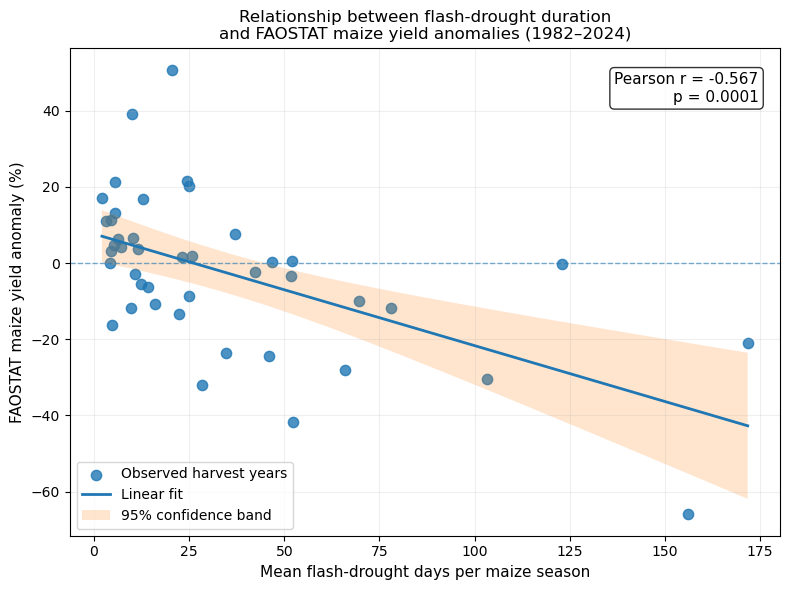


Saved:
C:\Users\franc\faostat_flash_drought_maize_yield_correlation_1982_2024_95CI.png


In [10]:
# ============================================================
# FLASH DROUGHT × FAOSTAT MAIZE YIELD ANOMALIES
# WITH 95% CONFIDENCE BAND
# ============================================================

import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, linregress, t

# ============================================================
# 1. LOAD FAOSTAT YIELD ANOMALIES
# ============================================================

fao_file = (
    r"C:\Users\franc\faostat_maize_yield_anomalies_LOWESS_1982_2024.csv"
)

fao = pd.read_csv(fao_file)

# ============================================================
# 2. LOAD FLASH DROUGHT + MAIZE MASK
# ============================================================

fd_file = (
    r"C:\Users\franc\flash_drought_events_1982_2025_final.nc"
)

mask_file = (
    r"C:\Users\franc\spam2020_sa_maize_mask_cdhw_grid.nc"
)

fd_ds = xr.open_dataset(
    fd_file,
    decode_timedelta=False
)

mask_ds = xr.open_dataset(
    mask_file,
    decode_timedelta=False
)

# ============================================================
# 3. FLASH-DROUGHT TOTAL DURATION
# ============================================================

fd_duration = fd_ds["fd_total_duration"]

# Match coordinate names
fd_duration = fd_duration.rename({
    "lat": "latitude",
    "lon": "longitude"
})

# ============================================================
# 4. REGRID TO MAIZE/CDHW GRID
# ============================================================

fd_regridded = fd_duration.interp(
    latitude=mask_ds["latitude"],
    longitude=mask_ds["longitude"],
    method="nearest"
)

print(
    "Regridded flash-drought shape:",
    fd_regridded.shape
)

# ============================================================
# 5. APPLY MAIZE-GROWING MASK
# ============================================================

maize_mask = (
    mask_ds["maize_cultivated"] == 1
)

fd_maize = fd_regridded.where(
    maize_mask
)

fd_mean = fd_maize.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

fd_annual = pd.DataFrame({
    "Harvest_Year":
        fd_ds["harvest_year"].values.astype(int),

    "Mean_Flash_Drought_Days":
        fd_mean.values
})

# ============================================================
# 6. MERGE WITH FAOSTAT YIELD ANOMALIES
# ============================================================

analysis = pd.merge(
    fao[
        [
            "Harvest_Year",
            "MYA",
            "MYA_percent"
        ]
    ],
    fd_annual,
    on="Harvest_Year",
    how="inner"
)

analysis = analysis.dropna(
    subset=[
        "MYA_percent",
        "Mean_Flash_Drought_Days"
    ]
).copy()

print("Number of observations:", len(analysis))

print(
    "Years:",
    analysis["Harvest_Year"].min(),
    "to",
    analysis["Harvest_Year"].max()
)

# ============================================================
# 7. PEARSON CORRELATION
# ============================================================

x = analysis[
    "Mean_Flash_Drought_Days"
].values

y = analysis[
    "MYA_percent"
].values

r, p = pearsonr(x, y)

print("\nFAOSTAT × Flash drought")
print("Pearson r =", round(r, 4))
print("p-value =", round(p, 6))

# ============================================================
# 8. LINEAR REGRESSION
# ============================================================

reg = linregress(x, y)

slope = reg.slope
intercept = reg.intercept

x_line = np.linspace(
    x.min(),
    x.max(),
    300
)

y_line = (
    intercept +
    slope * x_line
)

# ============================================================
# 9. 95% CONFIDENCE BAND
# ============================================================

n = len(x)

y_hat = (
    intercept +
    slope * x
)

residuals = y - y_hat

residual_standard_error = np.sqrt(
    np.sum(residuals**2) /
    (n - 2)
)

x_mean = np.mean(x)

Sxx = np.sum(
    (x - x_mean)**2
)

t_crit = t.ppf(
    0.975,
    df=n - 2
)

se_fit = residual_standard_error * np.sqrt(
    (1 / n) +
    ((x_line - x_mean)**2 / Sxx)
)

ci_lower = (
    y_line -
    t_crit * se_fit
)

ci_upper = (
    y_line +
    t_crit * se_fit
)

# ============================================================
# 10. PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)

ax.scatter(
    x,
    y,
    s=55,
    alpha=0.8,
    label="Observed harvest years"
)

ax.plot(
    x_line,
    y_line,
    linewidth=2,
    label="Linear fit"
)

ax.fill_between(
    x_line,
    ci_lower,
    ci_upper,
    alpha=0.20,
    label="95% confidence band"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

# ============================================================
# 11. LABELS
# ============================================================

ax.set_xlabel(
    "Mean flash-drought days per maize season",
    fontsize=11
)

ax.set_ylabel(
    "FAOSTAT maize yield anomaly (%)",
    fontsize=11
)

ax.set_title(
    "Relationship between flash-drought duration\n"
    "and FAOSTAT maize yield anomalies (1982–2024)",
    fontsize=12
)

# ============================================================
# 12. CORRELATION ANNOTATION
# ============================================================

ax.text(
    0.97,
    0.95,
    f"Pearson r = {r:.3f}\n"
    f"p = {p:.4f}",
    transform=ax.transAxes,
    horizontalalignment="right",
    verticalalignment="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.8
    )
)

ax.legend(
    loc="lower left",
    frameon=True
)

ax.grid(alpha=0.2)

plt.tight_layout()

# ============================================================
# 13. SAVE
# ============================================================

output_file = (
    r"C:\Users\franc\faostat_flash_drought_maize_yield_correlation_1982_2024_95CI.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(output_file)

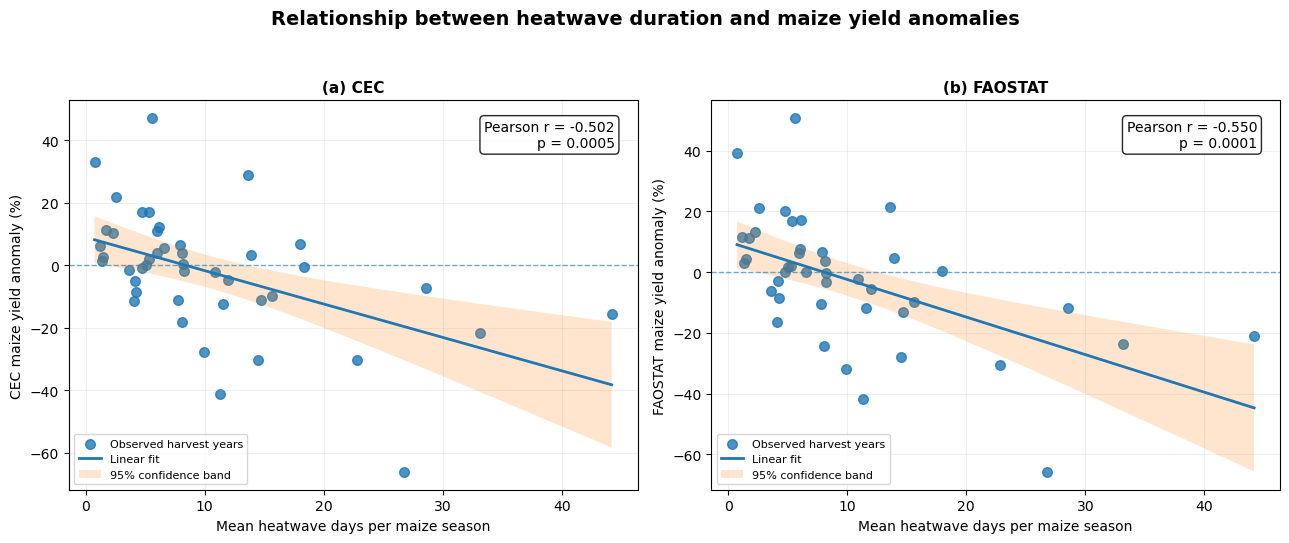


 heatwave duration
CEC: r = -0.5022 | p = 0.000513781021588356
FAOSTAT: r = -0.5499 | p = 0.00013378653485010048
Saved:
C:\Users\franc\heatwave_CEC_FAOSTAT_combined.png


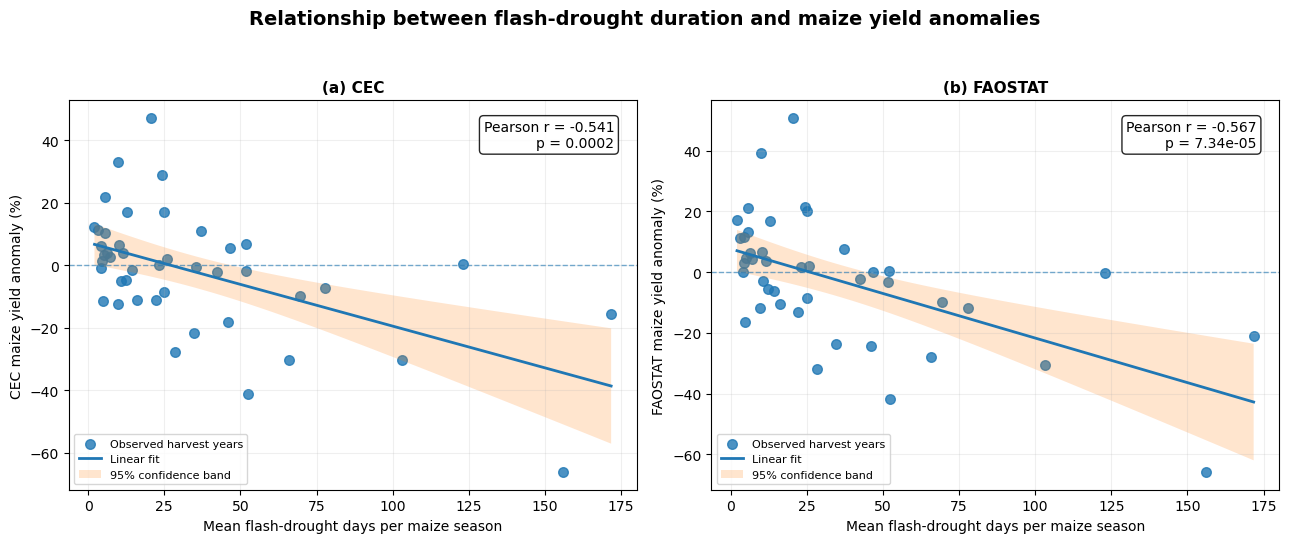


 flash-drought duration
CEC: r = -0.5407 | p = 0.00015113833776302048
FAOSTAT: r = -0.5671 | p = 7.344392659264137e-05
Saved:
C:\Users\franc\flash_drought_CEC_FAOSTAT_combined.png


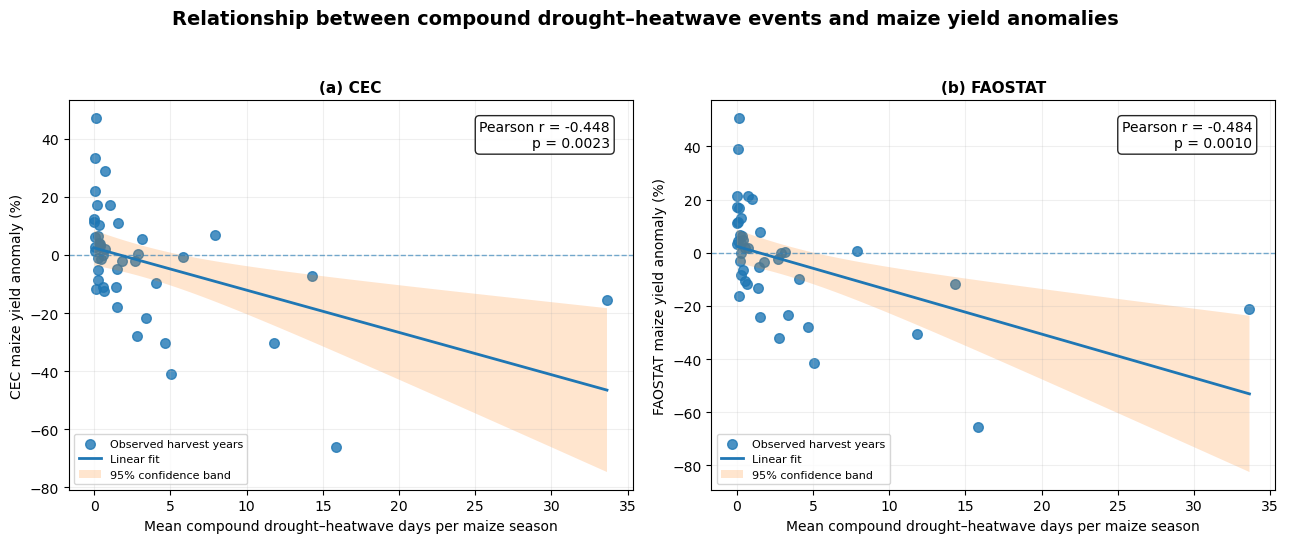


 compound drought–heatwave events
CEC: r = -0.4479 | p = 0.0022953906337457603
FAOSTAT: r = -0.4841 | p = 0.0010058348512003092
Saved:
C:\Users\franc\compound_CEC_FAOSTAT_combined.png


In [11]:
# ============================================================
# THREE COMBINED FIGURES
#
# Figure 1: Heatwave       -> CEC + FAOSTAT
# Figure 2: Flash drought  -> CEC + FAOSTAT
# Figure 3: Compound       -> CEC + FAOSTAT
#
# Each figure has:
#   - two panels
#   - linear regression
#   - 95% confidence band
#   - Pearson r and p-value
# ============================================================

import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, linregress, t


# ============================================================
# 1. FILE PATHS
# ============================================================

cec_file = (
    r"C:\Users\franc\maize_yield_anomalies_LOWESS_1982_2025.csv"
)

fao_file = (
    r"C:\Users\franc\faostat_maize_yield_anomalies_LOWESS_1982_2024.csv"
)

hw_file = (
    r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"
)

fd_file = (
    r"C:\Users\franc\flash_drought_events_1982_2025_final.nc"
)

compound_file = (
    r"C:\Users\franc\cdhw_severity_1982_2025.nc"
)

mask_file = (
    r"C:\Users\franc\spam2020_sa_maize_mask_cdhw_grid.nc"
)


# ============================================================
# 2. LOAD YIELD DATA
# ============================================================

cec = pd.read_csv(cec_file)
fao = pd.read_csv(fao_file)


# ============================================================
# 3. LOAD CLIMATE DATA
# ============================================================

hw_ds = xr.open_dataset(
    hw_file,
    decode_timedelta=False
)

fd_ds = xr.open_dataset(
    fd_file,
    decode_timedelta=False
)

compound_ds = xr.open_dataset(
    compound_file,
    decode_timedelta=False
)

mask_ds = xr.open_dataset(
    mask_file,
    decode_timedelta=False
)

maize_mask = (
    mask_ds["maize_cultivated"] == 1
)


# ============================================================
# 4. HEATWAVE SERIES
# ============================================================

hw_duration = hw_ds["hw_duration"]

hw_maize = hw_duration.where(
    maize_mask
)

hw_mean = hw_maize.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

hw_annual = pd.DataFrame({
    "Harvest_Year":
        hw_ds["harvest_year"].values.astype(int),

    "Climate_Value":
        hw_mean.values
})


# ============================================================
# 5. FLASH-DROUGHT SERIES
# ============================================================

fd_duration = fd_ds[
    "fd_total_duration"
].rename({
    "lat": "latitude",
    "lon": "longitude"
})

# Regrid to maize/CDHW grid
fd_regridded = fd_duration.interp(
    latitude=mask_ds["latitude"],
    longitude=mask_ds["longitude"],
    method="nearest"
)

fd_maize = fd_regridded.where(
    maize_mask
)

fd_mean = fd_maize.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

fd_annual = pd.DataFrame({
    "Harvest_Year":
        fd_ds["harvest_year"].values.astype(int),

    "Climate_Value":
        fd_mean.values
})


# ============================================================
# 6. COMPOUND SERIES
# ============================================================

compound = compound_ds[
    "cdhw_simultaneous_days"
]

compound_maize = compound.where(
    maize_mask
)

compound_mean = compound_maize.mean(
    dim=["latitude", "longitude"],
    skipna=True
)

compound_annual = pd.DataFrame({
    "Harvest_Year":
        compound_ds["harvest_year"].values.astype(int),

    "Climate_Value":
        compound_mean.values
})


# ============================================================
# 7. FUNCTION TO DRAW ONE PANEL
# ============================================================

def regression_panel(
    ax,
    yield_df,
    climate_df,
    source_name,
    x_label,
    panel_label
):

    # --------------------------------------------------------
    # Merge yield and climate
    # --------------------------------------------------------

    data = pd.merge(
        yield_df[
            [
                "Harvest_Year",
                "MYA_percent"
            ]
        ],
        climate_df,
        on="Harvest_Year",
        how="inner"
    )

    data = data.dropna(
        subset=[
            "MYA_percent",
            "Climate_Value"
        ]
    )

    x = data["Climate_Value"].values
    y = data["MYA_percent"].values

    # --------------------------------------------------------
    # Pearson correlation
    # --------------------------------------------------------

    r, p = pearsonr(x, y)

    # --------------------------------------------------------
    # Linear regression
    # --------------------------------------------------------

    reg = linregress(x, y)

    slope = reg.slope
    intercept = reg.intercept

    x_line = np.linspace(
        x.min(),
        x.max(),
        300
    )

    y_line = (
        intercept +
        slope * x_line
    )

    # --------------------------------------------------------
    # 95% confidence band
    # --------------------------------------------------------

    n = len(x)

    y_hat = (
        intercept +
        slope * x
    )

    residuals = y - y_hat

    residual_standard_error = np.sqrt(
        np.sum(residuals**2) /
        (n - 2)
    )

    x_mean = np.mean(x)

    Sxx = np.sum(
        (x - x_mean)**2
    )

    t_crit = t.ppf(
        0.975,
        df=n - 2
    )

    se_fit = (
        residual_standard_error *
        np.sqrt(
            (1 / n) +
            ((x_line - x_mean)**2 / Sxx)
        )
    )

    ci_lower = (
        y_line -
        t_crit * se_fit
    )

    ci_upper = (
        y_line +
        t_crit * se_fit
    )

    # --------------------------------------------------------
    # Scatter
    # --------------------------------------------------------

    ax.scatter(
        x,
        y,
        s=48,
        alpha=0.8,
        label="Observed harvest years"
    )

    # Regression
    ax.plot(
        x_line,
        y_line,
        linewidth=2,
        label="Linear fit"
    )

    # Confidence band
    ax.fill_between(
        x_line,
        ci_lower,
        ci_upper,
        alpha=0.20,
        label="95% confidence band"
    )

    # Zero anomaly
    ax.axhline(
        0,
        linestyle="--",
        linewidth=1,
        alpha=0.6
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_xlabel(
        x_label,
        fontsize=10
    )

    ax.set_ylabel(
        f"{source_name} maize yield anomaly (%)",
        fontsize=10
    )

    ax.set_title(
        f"({panel_label}) {source_name}",
        fontsize=11,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Correlation box
    # --------------------------------------------------------

    if p < 0.0001:
        p_text = f"{p:.2e}"
    else:
        p_text = f"{p:.4f}"

    ax.text(
        0.96,
        0.95,
        f"Pearson r = {r:.3f}\n"
        f"p = {p_text}",
        transform=ax.transAxes,
        horizontalalignment="right",
        verticalalignment="top",
        fontsize=10,
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.85
        )
    )

    ax.grid(
        alpha=0.20
    )

    ax.legend(
        loc="lower left",
        fontsize=8,
        frameon=True
    )

    return r, p


# ============================================================
# 8. FUNCTION TO CREATE ONE TWO-PANEL FIGURE
# ============================================================

def make_combined_figure(
    climate_df,
    event_name,
    x_label,
    output_file
):

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 5.5)
    )

    # CEC
    r_cec, p_cec = regression_panel(
        axes[0],
        cec,
        climate_df,
        "CEC",
        x_label,
        "a"
    )

    # FAOSTAT
    r_fao, p_fao = regression_panel(
        axes[1],
        fao,
        climate_df,
        "FAOSTAT",
        x_label,
        "b"
    )

    fig.suptitle(
        f"Relationship between {event_name} and maize yield anomalies",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.94]
    )

    # Save PNG
    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("\n", event_name)
    print(
        "CEC:",
        "r =", round(r_cec, 4),
        "| p =", p_cec
    )

    print(
        "FAOSTAT:",
        "r =", round(r_fao, 4),
        "| p =", p_fao
    )

    print("Saved:")
    print(output_file)


# ============================================================
# 9. FIGURE 1 — HEATWAVE
# ============================================================

make_combined_figure(

    climate_df=hw_annual,

    event_name="heatwave duration",

    x_label=(
        "Mean heatwave days per maize season"
    ),

    output_file=(
        r"C:\Users\franc\heatwave_CEC_FAOSTAT_combined.png"
    )
)


# ============================================================
# 10. FIGURE 2 — FLASH DROUGHT
# ============================================================

make_combined_figure(

    climate_df=fd_annual,

    event_name="flash-drought duration",

    x_label=(
        "Mean flash-drought days per maize season"
    ),

    output_file=(
        r"C:\Users\franc\flash_drought_CEC_FAOSTAT_combined.png"
    )
)


# ============================================================
# 11. FIGURE 3 — COMPOUND
# ============================================================

make_combined_figure(

    climate_df=compound_annual,

    event_name="compound drought–heatwave events",

    x_label=(
        "Mean compound drought–heatwave days per maize season"
    ),

    output_file=(
        r"C:\Users\franc\compound_CEC_FAOSTAT_combined.png"
    )
)

In [12]:
from PIL import Image
from pathlib import Path

# ============================================================
# ORIGINAL FIGURES
# ============================================================

files = [
    Path(r"C:\Users\franc\heatwave_CEC_FAOSTAT_combined.png"),
    Path(r"C:\Users\franc\flash_drought_CEC_FAOSTAT_combined.png"),
    Path(r"C:\Users\franc\compound_CEC_FAOSTAT_combined.png"),
]

# ============================================================
# CREATE OVERLEAF-FRIENDLY COPIES
# ============================================================

MAX_WIDTH = 1800

for file in files:

    img = Image.open(file)

    width, height = img.size

    if width > MAX_WIDTH:
        new_height = int(
            height * (MAX_WIDTH / width)
        )

        img = img.resize(
            (MAX_WIDTH, new_height),
            Image.Resampling.LANCZOS
        )

    output_file = file.with_name(
        file.stem + "_OVERLEAF.png"
    )

    # Convert safely to RGB
    if img.mode not in ("RGB", "RGBA"):
        img = img.convert("RGB")

    img.save(
        output_file,
        format="PNG",
        optimize=True,
        dpi=(150, 150)
    )

    print("Created:")
    print(output_file)
    print("Size:", img.size)
    print()

Created:
C:\Users\franc\heatwave_CEC_FAOSTAT_combined_OVERLEAF.png
Size: (1800, 757)

Created:
C:\Users\franc\flash_drought_CEC_FAOSTAT_combined_OVERLEAF.png
Size: (1800, 757)

Created:
C:\Users\franc\compound_CEC_FAOSTAT_combined_OVERLEAF.png
Size: (1800, 758)



In [13]:
from scipy.stats import linregress
import pandas as pd

# ============================================================
# EXACT COMPOUND-EVENT REGRESSION SLOPES
# ============================================================

def calculate_impact(yield_df, climate_df, source):

    data = pd.merge(
        yield_df[
            ["Harvest_Year", "MYA_percent"]
        ],
        climate_df,
        on="Harvest_Year",
        how="inner"
    ).dropna()

    result = linregress(
        data["Climate_Value"],
        data["MYA_percent"]
    )

    print(f"\n{source}")
    print("=" * 40)

    print(
        "Slope:",
        round(result.slope, 4),
        "percentage points per compound day"
    )

    print(
        "Intercept:",
        round(result.intercept, 4)
    )

    print(
        "R-squared:",
        round(result.rvalue**2, 4)
    )

    print(
        "p-value:",
        result.pvalue
    )

    print(
        "Estimated change for +5 compound days:",
        round(result.slope * 5, 2),
        "percentage points"
    )

    print(
        "Estimated change for +10 compound days:",
        round(result.slope * 10, 2),
        "percentage points"
    )


# CEC
calculate_impact(
    cec,
    compound_annual,
    "CEC"
)

# FAOSTAT
calculate_impact(
    fao,
    compound_annual,
    "FAOSTAT"
)


CEC
Slope: -1.4543 percentage points per compound day
Intercept: 2.4259
R-squared: 0.2006
p-value: 0.0022953906337457664
Estimated change for +5 compound days: -7.27 percentage points
Estimated change for +10 compound days: -14.54 percentage points

FAOSTAT
Slope: -1.6508 percentage points per compound day
Intercept: 2.4168
R-squared: 0.2343
p-value: 0.0010058348512003092
Estimated change for +5 compound days: -8.25 percentage points
Estimated change for +10 compound days: -16.51 percentage points
